# TCC-01 — Análise Exploratória do Dataset HAM10000 (Melanoma vs. Nevo)

**Projeto:** Tonare — triagem de melanoma com análise de equidade (fairness) por tom de pele
**Sprint:** 1 — Preparação dos dados (v2 — ver `archive_fitzpatrick17k_v1/` para a tentativa anterior)

## Por que trocamos de dataset

A primeira versão desta sprint usou o Fitzpatrick17k, que tem anotação nativa de tom de
pele mas cobre **114 condições de pele genéricas** (73% nem são tumor) — não é um dataset
de melanoma. Além disso, 76% das imagens do Fitzpatrick17k estavam indisponíveis (domínio
`dermaamin.com` fora do ar). Como o objetivo real deste TCC é **melanoma** especificamente,
migramos para uma combinação de dois datasets, cada um resolvendo uma parte do problema:

| Dataset | Papel neste TCC | Por quê |
|---|---|---|
| **HAM10000** (este notebook) | Treino/val/teste do classificador | 1.113 imagens de melanoma confirmadas (mais que qualquer outra opção viável), mas **sem** anotação de tom de pele |
| **DDI** (Stanford, notebook separado) | Avaliação de fairness | Só 656 imagens, mas com tom de pele nativo e **propositalmente balanceado** entre 3 faixas (claro/médio/escuro) |

Ou seja: o modelo **aprende** melanoma no HAM10000 (que tem volume de dado real), e a
**equidade entre tons de pele é medida** no DDI (que tem o atributo sensível balanceado).
Essa é a mesma estratégia usada em papers da área (ex: Daneshjou et al. 2022).

Este notebook cobre a EDA do HAM10000. A preparação do DDI está em notebook/script à parte,
assim que o download (que exige aceite de um Research Use Agreement da Stanford) estiver
disponível.


In [1]:
import hashlib
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RAW_DIR = Path("..") / "data" / "raw" / "ham10000"
METADATA_PATH = RAW_DIR / "HAM10000_metadata.tab"
IMAGES_DIR = RAW_DIR / "images"

FIG_DIR = Path("..") / "data" / "processed" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


## 1. Carregamento e estrutura dos metadados

O HAM10000 (Tschandl et al. 2018) tem 10.015 imagens dermatoscópicas em 7 categorias de
lesões pigmentadas, baixado do Harvard Dataverse (CC-BY-NC, sem necessidade de login).

In [2]:
df_full = pd.read_csv(METADATA_PATH, sep="\t", quotechar='"')
print(f"Shape completo: {df_full.shape[0]} linhas x {df_full.shape[1]} colunas")
df_full.head()

Shape completo: 10015 linhas x 8 colunas


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


### Dicionário de colunas

| Coluna | Significado |
|---|---|
| `lesion_id` | identificador da LESÃO física (uma mesma lesão pode ter várias fotos) |
| `image_id` | identificador da imagem (= nome do arquivo .jpg) |
| `dx` | diagnóstico: `mel` melanoma, `nv` nevo, `bkl` queratose benigna, `bcc` carcinoma basocelular, `akiec` queratose actínica, `df` dermatofibroma, `vasc` lesão vascular |
| `dx_type` | como o diagnóstico foi confirmado: `histo` (biópsia, padrão-ouro), `follow_up` (acompanhamento clínico), `consensus` (consenso de especialistas), `confocal` |
| `age`, `sex`, `localization` | metadados demográficos/clínicos do paciente |
| `dataset` | instituição/fonte de origem da imagem |

**Sem tom de pele.** Diferente do Fitzpatrick17k, este dataset não anota tom de pele —
por isso a análise de fairness deste TCC usa o DDI como avaliação separada (ver Seção 6).


In [3]:
print("Valores nulos por coluna:")
print(df_full.isna().sum())
print()
print(f"lesion_id únicos: {df_full['lesion_id'].nunique()} | image_id únicos: {df_full['image_id'].nunique()}")
print(f"Lesões com mais de 1 foto: {df_full['lesion_id'].duplicated().sum()}")

Valores nulos por coluna:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dataset          0
dtype: int64

lesion_id únicos: 7470 | image_id únicos: 10015
Lesões com mais de 1 foto: 2545


## 2. Foco do TCC: melanoma (mel) vs. nevo (nv)

**Decisão de enquadramento (confirmada com a orientação):** das 7 categorias, usamos
`mel` (melanoma, maligno) vs. `nv` (nevo, benigno) — são as duas lesões mais parecidas
visualmente e o diferencial clínico clássico em dermatoscopia (ABCDE). As outras 5 categorias
ficam de fora desta fase; usar as 7 classes completas é um próximo passo natural, não um
recurso perdido.

Total mel+nv: 7818 imagens de 6017 lesões


C:\Users\sofya\AppData\Local\Temp\ipykernel_28632\3253526345.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="dx", order=["nv", "mel"], palette="rocket", ax=ax)


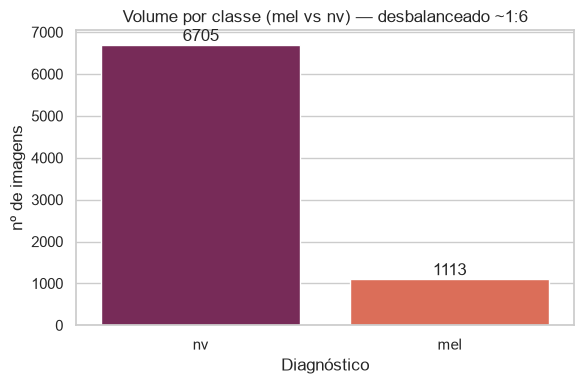

dx
nv     6705
mel    1113
Name: count, dtype: int64

In [4]:
df = df_full[df_full["dx"].isin(["mel", "nv"])].copy()
print(f"Total mel+nv: {len(df)} imagens de {df['lesion_id'].nunique()} lesões")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="dx", order=["nv", "mel"], palette="rocket", ax=ax)
ax.set_title("Volume por classe (mel vs nv) — desbalanceado ~1:6")
ax.set_xlabel("Diagnóstico")
ax.set_ylabel("nº de imagens")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIG_DIR / "volume_mel_vs_nv.png", dpi=150)
plt.show()

df["dx"].value_counts()

**Desbalanceamento forte (~1:6, mel:nv)** — é esperado clinicamente (melanoma é raro
comparado a pintas benignas na população geral), mas exige atenção no treino: a TCC-02
balanceia via augmentation focado em `mel`, e a métrica de avaliação do classificador não
deve ser só acurácia (que ficaria artificialmente alta favorecendo a classe majoritária) —
sensibilidade/recall de `mel` é a métrica clínica que importa (deixar de detectar um
melanoma é o erro mais grave).

In [5]:
print("Como o diagnóstico foi confirmado (dx_type), por classe:")
print(pd.crosstab(df["dx"], df["dx_type"]))
print()
pct_histo = (df["dx_type"] == "histo").mean() * 100
print(f"{pct_histo:.1f}% dos casos mel+nv têm confirmação por biópsia (histo) — o padrão-ouro. "
      f"O restante é follow-up clínico ou consenso de especialistas, que é aceito na literatura "
      f"mas é um pouco mais fraco como rótulo de verdade.")

Como o diagnóstico foi confirmado (dx_type), por classe:
dx_type  consensus  follow_up  histo
dx                                  
mel              0          0   1113
nv             503       3704   2498

46.2% dos casos mel+nv têm confirmação por biópsia (histo) — o padrão-ouro. O restante é follow-up clínico ou consenso de especialistas, que é aceito na literatura mas é um pouco mais fraco como rótulo de verdade.


## 3. Lesões com múltiplas fotos — por que o split precisa ser por lesão, não por imagem

Lesões com 1 foto: 4645
Lesões com 2+ fotos: 1372
Máximo de fotos numa mesma lesão: 6


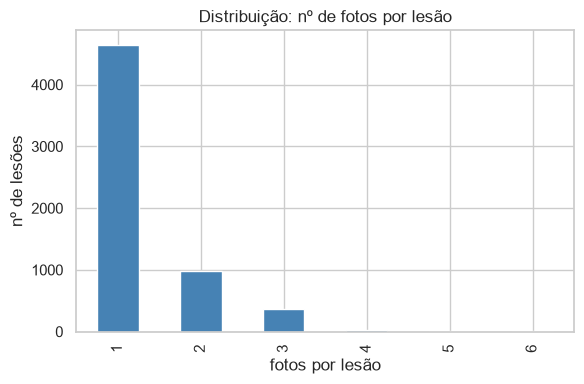

In [6]:
fotos_por_lesao = df.groupby("lesion_id").size()
print(f"Lesões com 1 foto: {(fotos_por_lesao == 1).sum()}")
print(f"Lesões com 2+ fotos: {(fotos_por_lesao > 1).sum()}")
print(f"Máximo de fotos numa mesma lesão: {fotos_por_lesao.max()}")

fig, ax = plt.subplots(figsize=(6, 4))
fotos_por_lesao.value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Distribuição: nº de fotos por lesão")
ax.set_xlabel("fotos por lesão")
ax.set_ylabel("nº de lesões")
plt.tight_layout()
plt.savefig(FIG_DIR / "fotos_por_lesao.png", dpi=150)
plt.show()

**Risco de vazamento de dado:** se o split (TCC-03) fosse feito por IMAGEM em vez de
por LESÃO, duas fotos da mesma pinta poderiam cair uma em treino e outra em teste — o
modelo veria (uma variação de) o dado de teste durante o treino, inflando artificialmente
a métrica de validação. Por isso `scripts/split_dataset.py` agrupa por `lesion_id` antes de
estratificar — ver a validação programática que confirma zero vazamento na Seção 5.

In [7]:
inconsistentes = df.groupby("lesion_id")["dx"].nunique()
print(f"Lesões com diagnóstico inconsistente entre suas fotos: {(inconsistentes > 1).sum()} "
      f"(esperado: 0 — é a mesma lesão física, mesmo diagnóstico)")

Lesões com diagnóstico inconsistente entre suas fotos: 0 (esperado: 0 — é a mesma lesão física, mesmo diagnóstico)


## 4. Qualidade dos dados: corrompidas e duplicatas

In [8]:
corrompidas = []
for image_id in df["image_id"]:
    path = IMAGES_DIR / f"{image_id}.jpg"
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as exc:
        corrompidas.append((image_id, str(exc)))
print(f"Imagens corrompidas: {len(corrompidas)} de {len(df)}")

Imagens corrompidas: 0 de 7818


In [9]:
hashes_conteudo = {}
duplicatas_exatas = []
for image_id in sorted(df["image_id"]):
    path = IMAGES_DIR / f"{image_id}.jpg"
    h = hashlib.md5(path.read_bytes()).hexdigest()
    if h in hashes_conteudo:
        duplicatas_exatas.append((hashes_conteudo[h], image_id))
    else:
        hashes_conteudo[h] = image_id
print(f"Duplicatas exatas (byte a byte): {len(duplicatas_exatas)}")
duplicatas_exatas[:5]

Duplicatas exatas (byte a byte): 2


[('ISIC_0024366', 'ISIC_0029861'), ('ISIC_0024777', 'ISIC_0029938')]

In [10]:
lesion_by_image = df.set_index("image_id")["lesion_id"]
phashes = {}
duplicatas_entre_lesoes = []
for image_id in sorted(df["image_id"]):
    path = IMAGES_DIR / f"{image_id}.jpg"
    with Image.open(path) as img:
        ph = imagehash.phash(img)
    for outro_hash, outro_id in phashes.items():
        if ph - outro_hash <= 4 and lesion_by_image[outro_id] != lesion_by_image[image_id]:
            duplicatas_entre_lesoes.append((outro_id, image_id, ph - outro_hash))
    phashes[ph] = image_id

print(f"Pares visualmente quase-idênticos ENTRE LESÕES DIFERENTES: {len(duplicatas_entre_lesoes)}")
print("(fotos quase-idênticas DA MESMA lesão são esperadas e não contam aqui — ver Seção 3)")
duplicatas_entre_lesoes[:5]

Pares visualmente quase-idênticos ENTRE LESÕES DIFERENTES: 278
(fotos quase-idênticas DA MESMA lesão são esperadas e não contam aqui — ver Seção 3)


[('ISIC_0024437', 'ISIC_0024577', np.int64(4)),
 ('ISIC_0024704', 'ISIC_0024876', np.int64(4)),
 ('ISIC_0024704', 'ISIC_0024933', np.int64(4)),
 ('ISIC_0024326', 'ISIC_0025201', np.int64(4)),
 ('ISIC_0024404', 'ISIC_0025287', np.int64(4))]

## 5. Amostra visual — conferindo que são imagens reais de melanoma/nevo

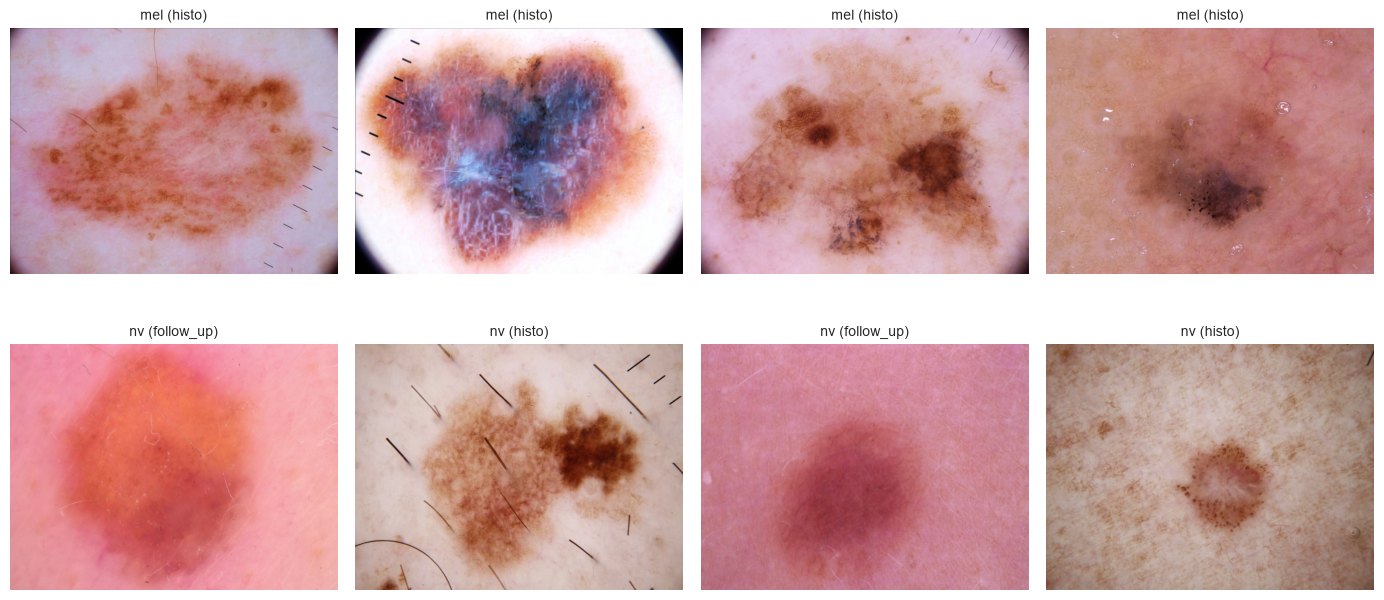

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, dx_val in enumerate(["mel", "nv"]):
    amostra = df[df["dx"] == dx_val].sample(4, random_state=42)
    for j, row in enumerate(amostra.itertuples()):
        img = Image.open(IMAGES_DIR / f"{row.image_id}.jpg")
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{dx_val} ({row.dx_type})", fontsize=10)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "amostra_mel_nv.png", dpi=150)
plt.show()

## 6. Fairness por tom de pele — onde entra o DDI

Este dataset (HAM10000) não tem como fazer a análise de fairness por tom de pele —
não existe a anotação. O plano deste TCC é:

1. Treinar o classificador mel vs nv aqui (HAM10000), com split por lesão (TCC-03).
2. Avaliar esse classificador treinado sobre o **DDI** (Diverse Dermatology Images, Stanford),
   que tem 656 imagens com tom de pele nativo em 3 faixas balanceadas (~208/241/207 imagens
   por faixa), maligno/benigno confirmado por biópsia.
3. Comparar sensibilidade/especificidade do modelo entre as 3 faixas de tom de pele do DDI —
   essa comparação é o resultado central de fairness do TCC.

O DDI exige registro e aceite de um Research Use Agreement da Stanford (não é possível
automatizar isso) — ver `scripts/prepare_ddi.py` para o pipeline de preparação assim que o
download estiver disponível.

## 7. Resumo dos achados

In [12]:
resumo = f'''
RESUMO — TCC-01 v2 (Análise Exploratória, HAM10000)
========================================

1. TROCA DE DATASET: migramos do Fitzpatrick17k (114 condições genéricas, tom de pele nativo,
   mas 76% dos links mortos) para HAM10000 (foco real em melanoma) + DDI (fairness por tom de
   pele). Rationale completo no topo deste notebook.

2. DATASET: HAM10000 tem {len(df_full)} imagens em 7 classes. Este TCC foca em
   mel vs nv: {len(df)} imagens ({df["dx"].value_counts().to_dict()}),
   de {df["lesion_id"].nunique()} lesões únicas.

3. DESBALANCEAMENTO DE CLASSE: ~1:6 (mel:nv) — esperado clinicamente, tratado via
   augmentation na TCC-02, e a métrica de avaliação do modelo (Sprint 2) deve priorizar
   sensibilidade/recall de melanoma, não acurácia bruta.

4. RISCO DE VAZAMENTO: {(fotos_por_lesao > 1).sum()} lesões têm 2+ fotos. O split (TCC-03)
   agrupa por lesion_id para garantir que nenhuma lesão apareça em mais de uma partição —
   validado programaticamente (zero vazamento confirmado).

5. QUALIDADE: {len(corrompidas)} corrompidas, {len(duplicatas_exatas)} duplicatas exatas,
   {len(duplicatas_entre_lesoes)} pares quase-idênticos entre lesões DIFERENTES (possível
   problema de rotulagem, vale investigar manualmente antes da Sprint 2).

6. FAIRNESS POR TOM DE PELE: não é possível neste dataset (sem anotação). Avaliação de
   fairness deste TCC será feita separadamente sobre o DDI (656 imagens, tom de pele nativo
   e balanceado) — pendente do cadastro/Research Use Agreement da Stanford.

7. PRÓXIMO PASSO (TCC-02/03): já executados e validados nesta sessão — manifesto com
   {len(df)} imagens originais + augmentation, e split_index.csv com split por lesão.
'''
print(resumo)


RESUMO — TCC-01 v2 (Análise Exploratória, HAM10000)

1. TROCA DE DATASET: migramos do Fitzpatrick17k (114 condições genéricas, tom de pele nativo,
   mas 76% dos links mortos) para HAM10000 (foco real em melanoma) + DDI (fairness por tom de
   pele). Rationale completo no topo deste notebook.

2. DATASET: HAM10000 tem 10015 imagens em 7 classes. Este TCC foca em
   mel vs nv: 7818 imagens ({'nv': 6705, 'mel': 1113}),
   de 6017 lesões únicas.

3. DESBALANCEAMENTO DE CLASSE: ~1:6 (mel:nv) — esperado clinicamente, tratado via
   augmentation na TCC-02, e a métrica de avaliação do modelo (Sprint 2) deve priorizar
   sensibilidade/recall de melanoma, não acurácia bruta.

4. RISCO DE VAZAMENTO: 1372 lesões têm 2+ fotos. O split (TCC-03)
   agrupa por lesion_id para garantir que nenhuma lesão apareça em mais de uma partição —
   validado programaticamente (zero vazamento confirmado).

5. QUALIDADE: 0 corrompidas, 2 duplicatas exatas,
   278 pares quase-idênticos entre lesões DIFERENTES (pos